In [1]:
%matplotlib inline

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [4]:
data = {
    "Study_Hours": [1, 2, 4, 5, 1, 2, 4, 5],
    "Attendance": [50, 60, 65, 70, 80, 85, 90, 95],
    "Result": [
        "Fail", "Fail", "Fail", "Fail",
        "Pass", "Pass", "Pass", "Pass"
    ]
}

df = pd.DataFrame(data)

In [5]:
print("Student Dataset:")
display(df)

Student Dataset:


,Study_Hours,Attendance,Result
0,1,50,Fail
1,2,60,Fail
2,4,65,Fail
3,5,70,Fail
4,1,80,Pass
5,2,85,Pass
6,4,90,Pass
7,5,95,Pass


In [6]:
X = df[["Study_Hours", "Attendance"]]
y = df["Result"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

In [7]:
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 6
Testing Records: 2


In [8]:
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=2,
    random_state=42
)

model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


[Text(0.5, 0.75, 'Attendance <= 75.0\ngini = 0.5\nsamples = 6\nvalue = [3, 3]\nclass = Fail'),
 Text(0.25, 0.25, 'gini = 0.0\nsamples = 3\nvalue = [3, 0]\nclass = Fail'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'gini = 0.0\nsamples = 3\nvalue = [0, 3]\nclass = Pass'),
 Text(0.625, 0.5, '  False')]

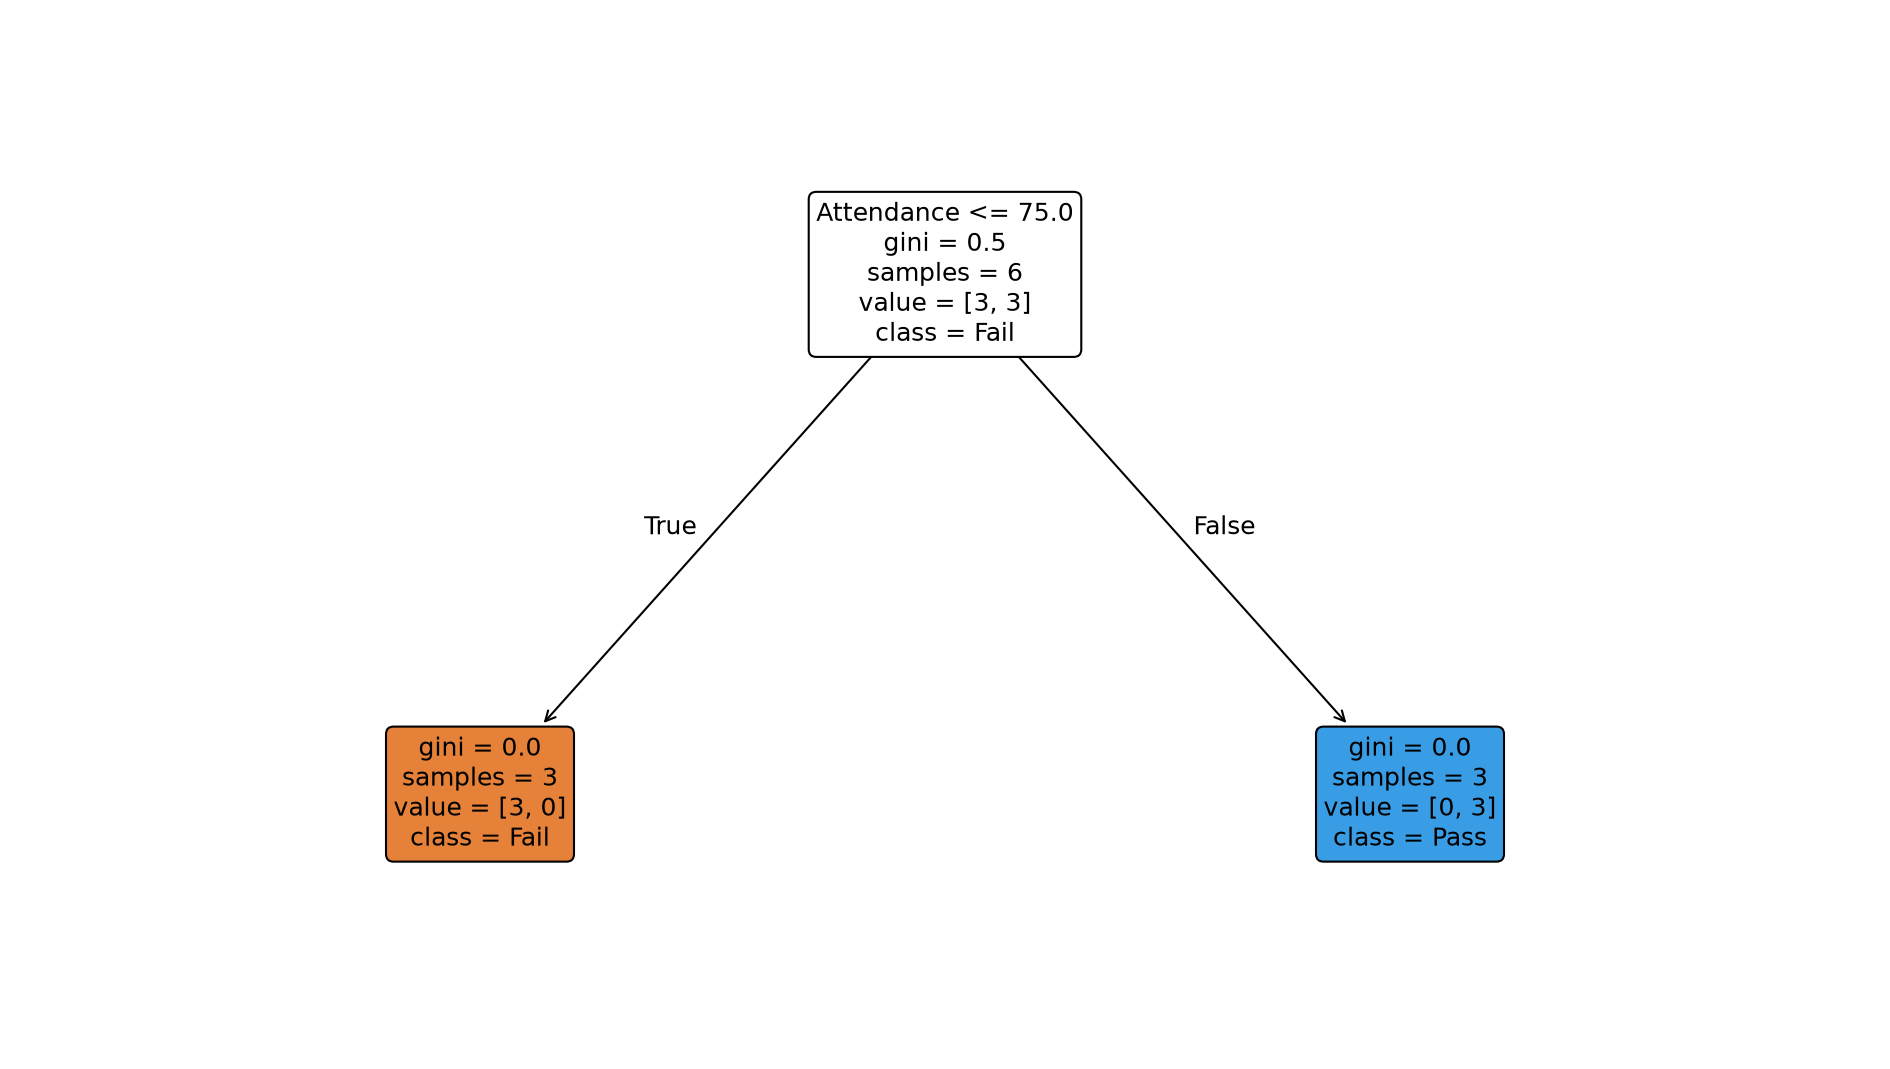

In [9]:
plt.figure(figsize=(16, 9), dpi=150)

plot_tree(
    model,
    feature_names=["Study_Hours", "Attendance"],
    class_names=["Fail", "Pass"],
    filled=True,
    rounded=True,
    proportion=False,
    precision=2,
    fontsize=12
)

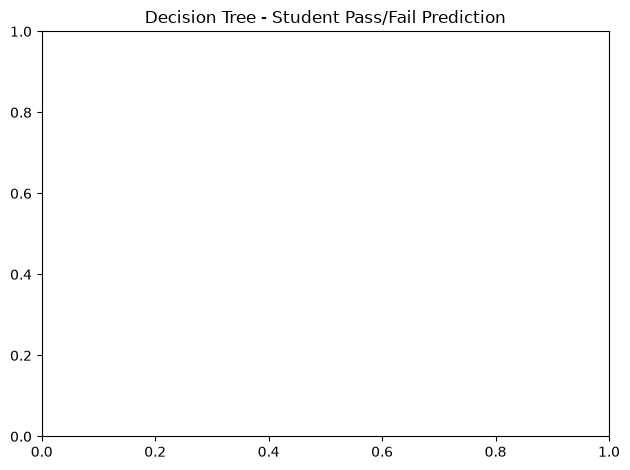

In [10]:
plt.title("Decision Tree - Student Pass/Fail Prediction")
plt.tight_layout()
plt.show()

In [11]:
y_pred = model.predict(X_test)

In [12]:
print("Actual Results:")
print(y_test.values)

Actual Results:
['Fail' 'Pass']


In [13]:
print("\nPredicted Results:")
print(y_pred)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")


Predicted Results:
['Fail' 'Pass']
Model Accuracy: 100.0 %


In [14]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Fail", "Pass"]
)

In [15]:
print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 4))

Confusion Matrix:
[[1 0]
 [0 1]]


<Figure size 600x400 with 0 Axes>

<Figure size 600x400 with 0 Axes>

<Axes: >

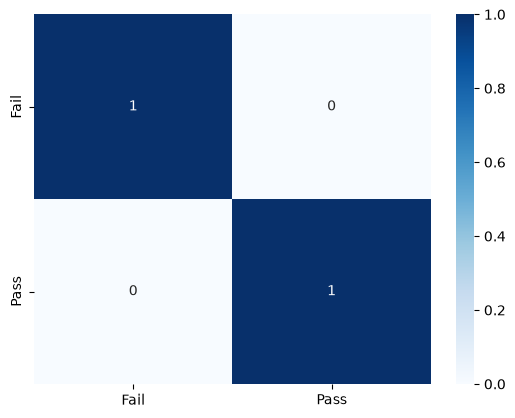

In [16]:
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

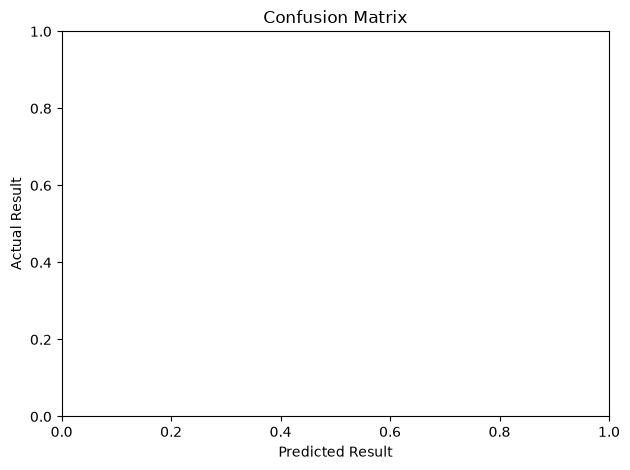

In [17]:
plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [18]:
print("Classification Report:")

Classification Report:


In [19]:
print(
    classification_report(
        y_test,
        y_pred,
        labels=["Fail", "Pass"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         1
        Pass       1.00      1.00      1.00         1

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2



In [20]:
new_student = pd.DataFrame({
    "Study_Hours": [4],
    "Attendance": [85]
})

prediction = model.predict(new_student)

In [21]:
print("New Student Details:")
display(new_student)

print("Predicted Student Result:", prediction[0])

New Student Details:


,Study_Hours,Attendance
0,4,85


Predicted Student Result: Pass


In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

In [23]:
# Calculate Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Fail", "Pass"]
)

In [24]:
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[1 0]
 [0 1]]


In [25]:
# Plot Confusion Matrix Heatmap
plt.figure(figsize=(6, 4))

<Figure size 600x400 with 0 Axes>

<Figure size 600x400 with 0 Axes>

<Axes: >

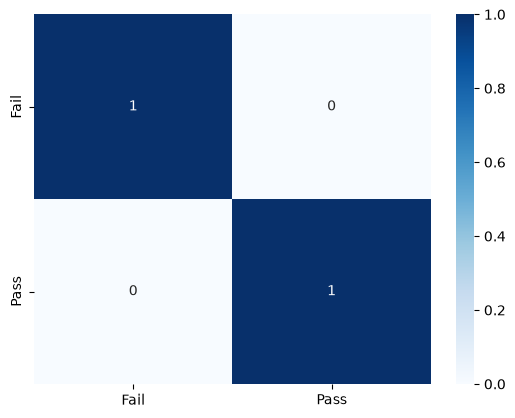

In [26]:
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

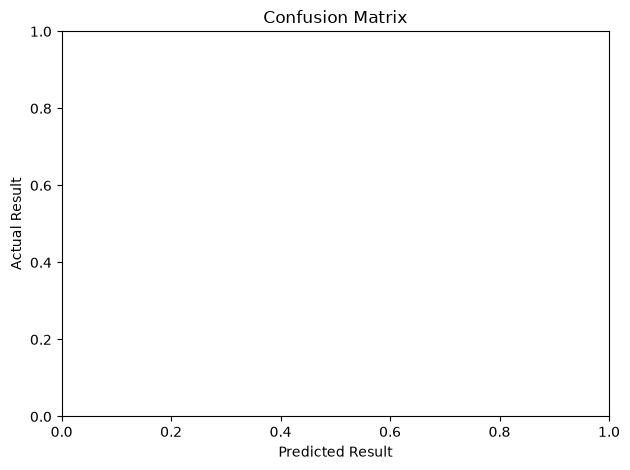

In [27]:
plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()